# Lecture: Clustering, Finding Structure Without Labels
*AI/ML in Physics (CWRU), Unit 1*

**Today's question:** you have a pile of measurements and no labels. Some of the points belong together. Which tools can do grouping like this, and how 'fancy' of a tool do you actually need?

### By the end of today you should be able to
1. Explain how k-means, DBSCAN and Gaussian mixture models decide what a "group" is.
2. Predict which one will fail on a given data set, and why, from its assumptions.
3. Explain why feature choice and scaling decisions are made
4. Name two ways to check a clustering result when there is no right answer to compare against.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

rng = np.random.default_rng(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = np.array(["#1D5FA8", "#C2410C", "#2F9E6E", "#7C3AED", "#B45309", "#0E7490"])

def color_of(labels):
    '''Map cluster labels to colors; noise (-1) is light gray.'''
    labels = np.asarray(labels)
    out = np.empty((labels.size, 4))
    out[:] = (0.8, 0.8, 0.8, 0.6)
    for k in np.unique(labels[labels >= 0]):
        out[labels == k] = plt.matplotlib.colors.to_rgba(COLORS[k % len(COLORS)])
    return out

---
## 1. The hook: you can see it, can a computer?

Below are 1,500 "stars" plotted by their proper motion (how fast they drift across the sky). Most are field stars moving every which way. A few hundred were born together in clusters and move together.

**Pause and predict:** how many clusters do you see? Write down a number before we run anything.

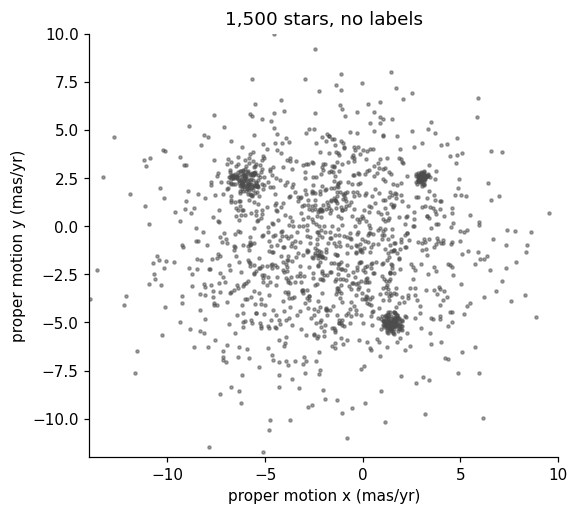

In [2]:
def toy_sky(seed=3):
    '''Three tight clumps inside a broad background, like Gaia proper motions.'''
    r = np.random.default_rng(seed)
    field = r.normal([-2, -1], [4.0, 3.5], size=(1200, 2))
    clumps = [r.normal(c, s, size=(n, 2)) for c, s, n in
              [((-6, 2.5), 0.45, 120), ((1.5, -5.0), 0.25, 110), ((3.0, 2.5), 0.15, 70)]]
    X = np.vstack([field] + clumps)
    y = np.concatenate([np.full(1200, -1)] + [np.full(len(c), i) for i, c in enumerate(clumps)])
    return X, y

X_sky, y_sky = toy_sky()
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*X_sky.T, s=4, alpha=0.5, color="0.3")
ax.set(xlabel="proper motion x (mas/yr)", ylabel="proper motion y (mas/yr)",
       title="1,500 stars, no labels", xlim=(-14, 10), ylim=(-12, 10))
plt.show()

Most people say three. Hold on to that number. By the end of the lecture we'll see one algorithm insist on three groups that are mostly the wrong stars, and another find all three clusters and correctly leave the field alone.

**Vocabulary for today** (same as the textbook, Acquaviva Ch. 1):
- **instance:** one row of data (one star, one particle track)
- **feature:** one measured number per instance (proper motion, parallax, momentum)
- **clustering:** grouping instances with no labels. It is *unsupervised* learning: the target is a pattern, not a known property.

---
## 2. Everything depends on "distance"

Clustering groups points that are *close*. So before choosing an algorithm, you have already made two choices that matter more:
1. **Which features** go in (which axes the points live on).
2. **How they are scaled** (how much one unit of each axis counts).

Here is the same data set clustered twice. The only difference is whether we standardize the features (subtract the mean, divide by the standard deviation).

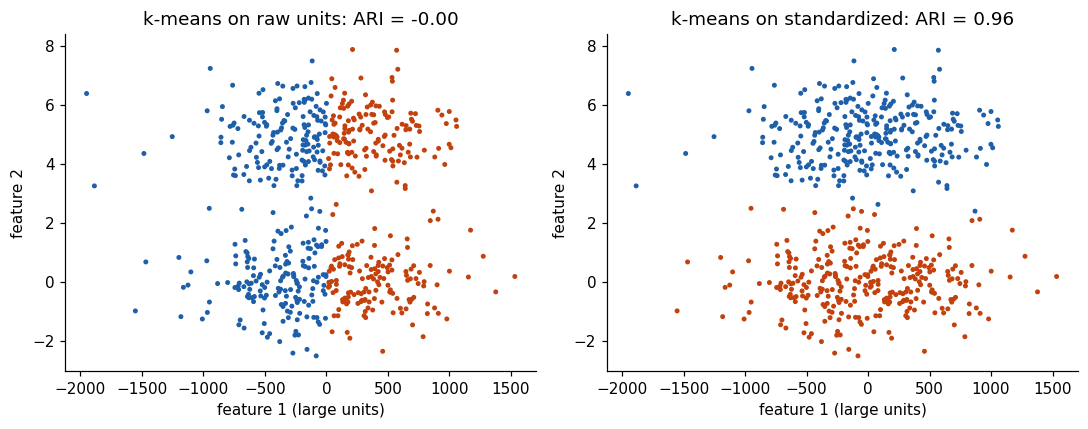

In [3]:
# Two populations that differ in feature 2 only. Feature 1 is in big units (e.g. meters vs km).
r = np.random.default_rng(0)
f1 = r.normal(0, 500, 600)                          # large spread, carries no information
f2 = np.concatenate([r.normal(0, 1, 300), r.normal(5, 1, 300)])
truth_scale = np.repeat([0, 1], 300)
X_raw = np.column_stack([f1, f2])

lab_raw = KMeans(2, n_init=10, random_state=0).fit_predict(X_raw)
lab_std = KMeans(2, n_init=10, random_state=0).fit_predict(StandardScaler().fit_transform(X_raw))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, lab, name in zip(axes, [lab_raw, lab_std], ["raw units", "standardized"]):
    ax.scatter(f1, f2, s=5, c=color_of(lab))
    ax.set(xlabel="feature 1 (large units)", ylabel="feature 2",
           title=f"k-means on {name}: ARI = {adjusted_rand_score(truth_scale, lab):.2f}")
plt.tight_layout(); plt.show()

**What happened:** in raw units, a 1-unit change in feature 2 is invisible next to a 500-unit spread in feature 1, so k-means splits along feature 1, which carries no information. Standardizing fixes it here.

**ARI** (adjusted Rand index) compares a clustering to the true labels: 1 is perfect agreement, 0 is no better than random. We can only compute it because this is simulated data.

> **Physics point:** scaling decides how much each measurement counts. Standardizing is a reasonable default, but it is still a choice. If you know one feature is measured 10 times more precisely, you might weight it by its uncertainty instead. You'll see in the assignment that the best fix is often a better feature, not a better scaling.

---
## 3. k-means

The simplest clustering algorithm, and still the most used.

1. Pick $k$ starting centers.
2. **Assign:** each point joins its nearest center.
3. **Update:** each center moves to the mean of its points.
4. Repeat 2 and 3 until nothing moves.

Each step can only lower the **inertia**, the total squared distance from points to their centers:
$$I = \sum_i \lVert \mathbf{x}_i - \boldsymbol{\mu}_{c(i)} \rVert^2 .$$

Let's watch it run on clean data first.

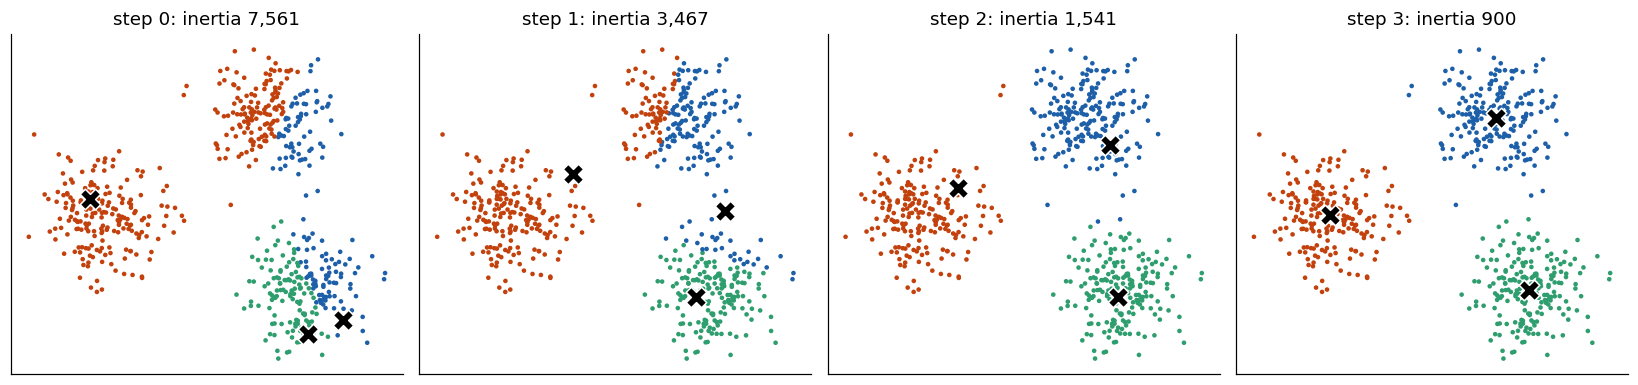

In [4]:
X_blob, y_blob = make_blobs(n_samples=600, centers=[(-3, 0), (2, 3), (3, -2)], cluster_std=0.9, random_state=4)

def kmeans_steps(X, k, n_steps, seed=2):
    '''Return the centers and labels after each assign/update step (for plotting).'''
    r = np.random.default_rng(seed)
    centers = X[r.choice(len(X), k, replace=False)]
    history = []
    for _ in range(n_steps):
        labels = np.linalg.norm(X[:, None] - centers[None], axis=2).argmin(1)
        history.append((centers.copy(), labels))
        centers = np.array([X[labels == j].mean(0) for j in range(k)])
    return history

hist = kmeans_steps(X_blob, 3, 4)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for i, (ax, (cen, lab)) in enumerate(zip(axes, hist)):
    ax.scatter(*X_blob.T, s=4, c=color_of(lab))
    ax.scatter(*cen.T, marker="X", s=180, c="k", edgecolors="w")
    inertia = ((X_blob - cen[lab]) ** 2).sum()
    ax.set(title=f"step {i}: inertia {inertia:,.0f}", xticks=[], yticks=[])
plt.tight_layout(); plt.show()

### Choosing $k$
k-means needs you to tell it $k$. Two common guides:
- **Elbow:** plot inertia against $k$ and look for the bend. Inertia always drops as $k$ grows, so you're looking for where adding clusters stops paying off.
- **Silhouette score:** for each point, compares the distance to its own cluster with the distance to the next-nearest cluster. Ranges from −1 to 1; higher is better. Unlike inertia, it can go *down* when you add too many clusters.

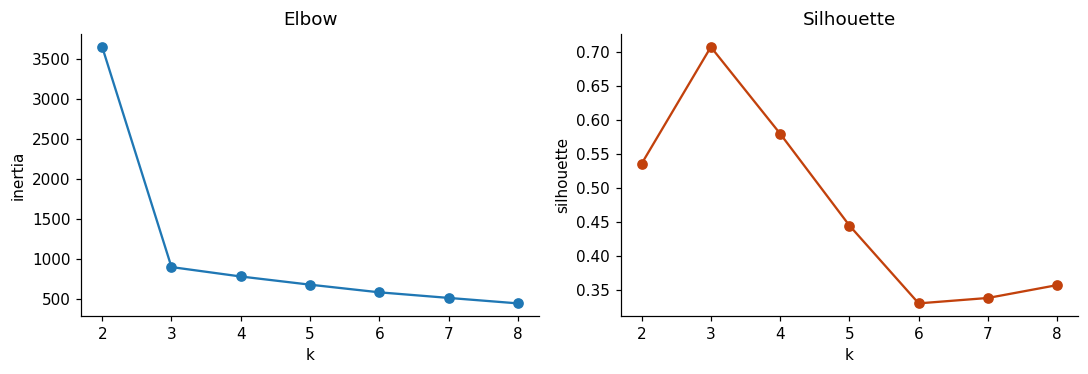

best k by silhouette: 3


In [5]:
ks = range(2, 9)
inertias, sils = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=0).fit(X_blob)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_blob, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set(xlabel="k", ylabel="inertia", title="Elbow")
axes[1].plot(list(ks), sils, "o-", color="#C2410C"); axes[1].set(xlabel="k", ylabel="silhouette", title="Silhouette")
plt.tight_layout(); plt.show()
print("best k by silhouette:", list(ks)[int(np.argmax(sils))])

**Pause and predict:** k-means just worked perfectly on clean blobs. Now go back to the star field from Section 1. If we run k-means with $k = 3$ there, where will the three centers land?

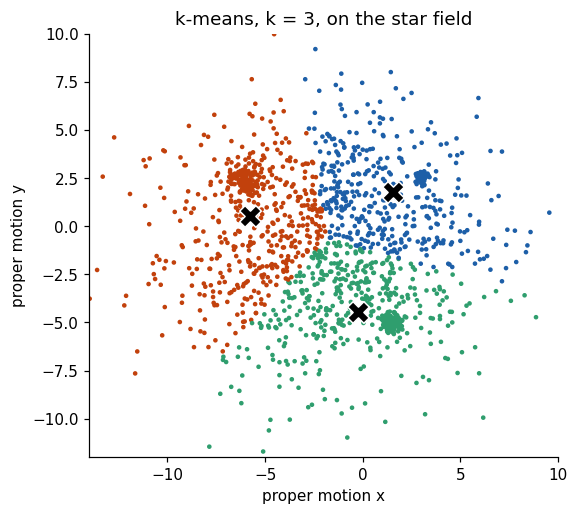

fraction of each k-means group that is actually cluster stars:
  group 0: 0.16
  group 1: 0.22
  group 2: 0.21


In [6]:
km_sky = KMeans(3, n_init=10, random_state=0).fit(X_sky)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*X_sky.T, s=4, c=color_of(km_sky.labels_))
ax.scatter(*km_sky.cluster_centers_.T, marker="X", s=200, c="k", edgecolors="w")
ax.set(xlabel="proper motion x", ylabel="proper motion y", xlim=(-14, 10), ylim=(-12, 10),
       title="k-means, k = 3, on the star field")
plt.show()
in_cluster = y_sky >= 0
print(f"fraction of each k-means group that is actually cluster stars:")
for j in range(3):
    print(f"  group {j}: {np.mean(in_cluster[km_sky.labels_ == j]):.2f}")

**What happened:** the field holds 80% of the stars, so the cheapest way to lower inertia is to cut the field into three big slices. The tight clusters barely change the total, so k-means ignores them. Every field star is also *forced* into some group, because k-means has no way to say "this point belongs to nothing."

This isn't a bug. k-means did exactly what it promises. It answered a different question from the one we asked.

---
## 4. Every algorithm has assumptions

k-means quietly assumes clusters are **round, about the same size, and cover every point**. Here are three data sets that each break one assumption. We'll reuse them for every algorithm today.

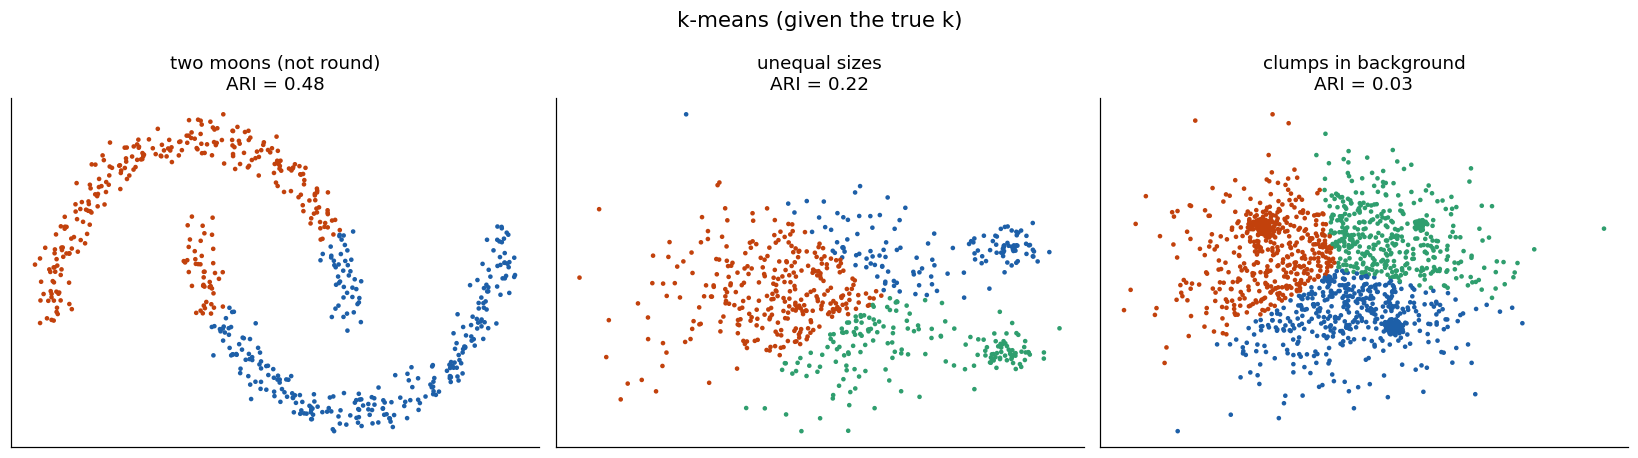

In [7]:
X_moons, y_moons = make_moons(n_samples=600, noise=0.06, random_state=0)

X_uneq, y_uneq = make_blobs(n_samples=[500, 60, 60], centers=[(0, 0), (4.2, 1.8), (4.2, -1.8)],
                            cluster_std=[1.6, 0.35, 0.35], random_state=1)

datasets = {
    "two moons (not round)": (StandardScaler().fit_transform(X_moons), y_moons, 2),
    "unequal sizes": (StandardScaler().fit_transform(X_uneq), y_uneq, 3),
    "clumps in background": (StandardScaler().fit_transform(X_sky), y_sky, 3),
}

def show_row(results, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    for ax, (name, (X, y, k)) in zip(axes, datasets.items()):
        lab = results[name]
        ax.scatter(*X.T, s=4, c=color_of(lab))
        ax.set(title=f"{name}\nARI = {adjusted_rand_score(y, lab):.2f}", xticks=[], yticks=[])
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

res_km = {name: KMeans(k, n_init=10, random_state=0).fit_predict(X) for name, (X, y, k) in datasets.items()}
show_row(res_km, "k-means (given the true k)")

Even with the correct $k$ handed to it, k-means cuts the moons in half, steals points from the big blob to feed the small ones, and slices the background.

For the background case we score against labels where all field stars share one label (−1). An algorithm that leaves the field alone and finds the three clumps gets a high score.

---
## 5. DBSCAN: clusters are dense regions

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) changes the definition of a cluster:
- A point is a **core point** if at least `min_samples` points lie within distance `eps` of it.
- Core points that are within `eps` of each other are linked into one cluster.
- Points near a cluster join it; everything else is **noise** (label −1).

You don't choose $k$; you choose a density. Points that aren't in any dense region are allowed to belong to nothing.

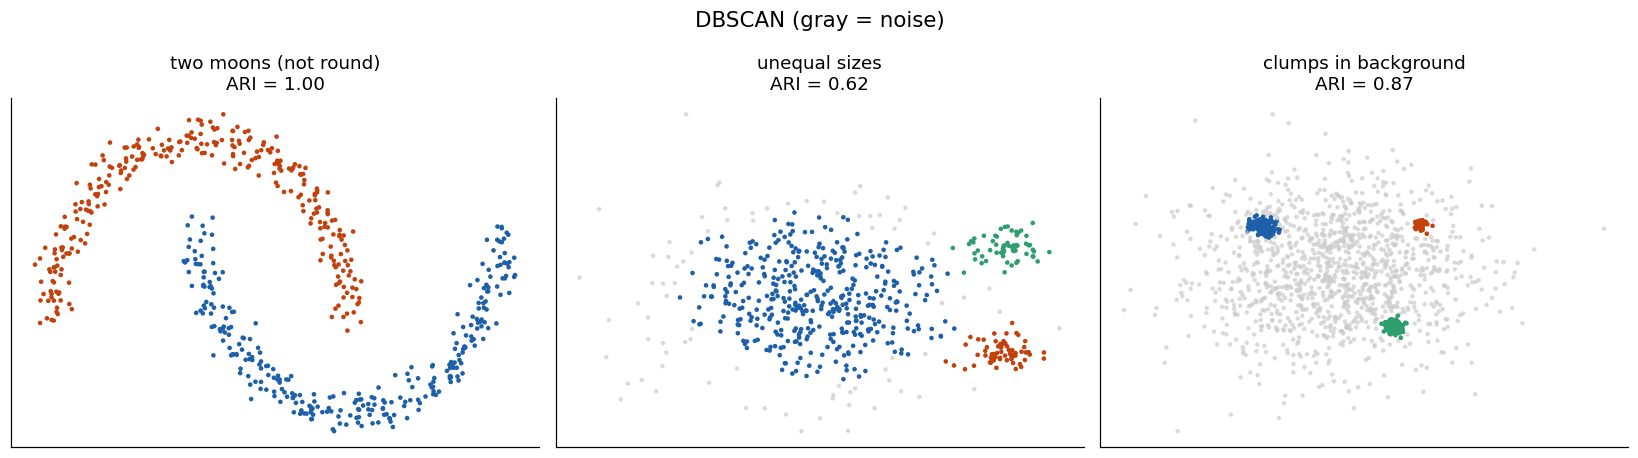

two moons (not round)     clusters found: 2   noise fraction: 0.00
unequal sizes             clusters found: 3   noise fraction: 0.13
clumps in background      clusters found: 3   noise fraction: 0.79


In [8]:
db_params = {"two moons (not round)": (0.25, 10), "unequal sizes": (0.3, 10), "clumps in background": (0.1, 20)}
res_db = {name: DBSCAN(eps=db_params[name][0], min_samples=db_params[name][1]).fit_predict(X)
          for name, (X, y, k) in datasets.items()}
show_row(res_db, "DBSCAN (gray = noise)")
for name, lab in res_db.items():
    print(f"{name:25s} clusters found: {lab.max() + 1}   noise fraction: {np.mean(lab == -1):.2f}")

DBSCAN follows the moons and finds the three star clusters while leaving the field as noise. On the unequal blobs it does worse: the big blob's sparse outer edge falls below the density cut and becomes "noise," even though those points belong to it.

The catch is the settings: I chose different `eps` and `min_samples` for each data set, and the right values depend on the density you're looking for. With one `eps`, clusters of very different densities are hard to find at the same time. **HDBSCAN** scans over densities to fix this, and you'll use it in the lab.

**Pause and predict:** what happens on the star field if `eps` is twice as large? Half as large?

In [9]:
X_s = datasets["clumps in background"][0]
for eps in [0.05, 0.1, 0.2]:
    lab = DBSCAN(eps=eps, min_samples=20).fit_predict(X_s)
    print(f"eps = {eps:<5} clusters = {lab.max() + 1:<3} noise fraction = {np.mean(lab == -1):.2f}  "
          f"ARI = {adjusted_rand_score(y_sky, lab):.2f}")

eps = 0.05  clusters = 2   noise fraction = 0.92  ARI = 0.49
eps = 0.1   clusters = 3   noise fraction = 0.79  ARI = 0.87
eps = 0.2   clusters = 6   noise fraction = 0.41  ARI = 0.21


Too small, and the most spread-out cluster drops below the density cut and disappears into the noise. Too large, and the dense middle of the field turns into fake clusters. A factor of two either way changes the answer.

---
## 6. Gaussian mixture models: clusters are probability blobs

A GMM assumes the data came from a sum of Gaussians:
$$p(\mathbf{x}) = \sum_{j=1}^{K} w_j\, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_j, \Sigma_j).$$
It fits each blob's weight $w_j$, center $\boldsymbol{\mu}_j$ and covariance $\Sigma_j$ (so blobs can be stretched ellipses of different sizes).

Two big differences from k-means:
1. **Soft membership:** each point gets a *probability* of belonging to each component. Real cluster catalogs publish membership probabilities, not yes/no labels.
2. **A principled way to choose $K$:** the Bayesian Information Criterion (BIC) rewards fitting the data and penalizes extra parameters. Lower is better.

A physicist's way to read it: a GMM is a model fit. You're fitting a sum of Gaussians to a density, the same way you'd fit peaks in a spectrum.

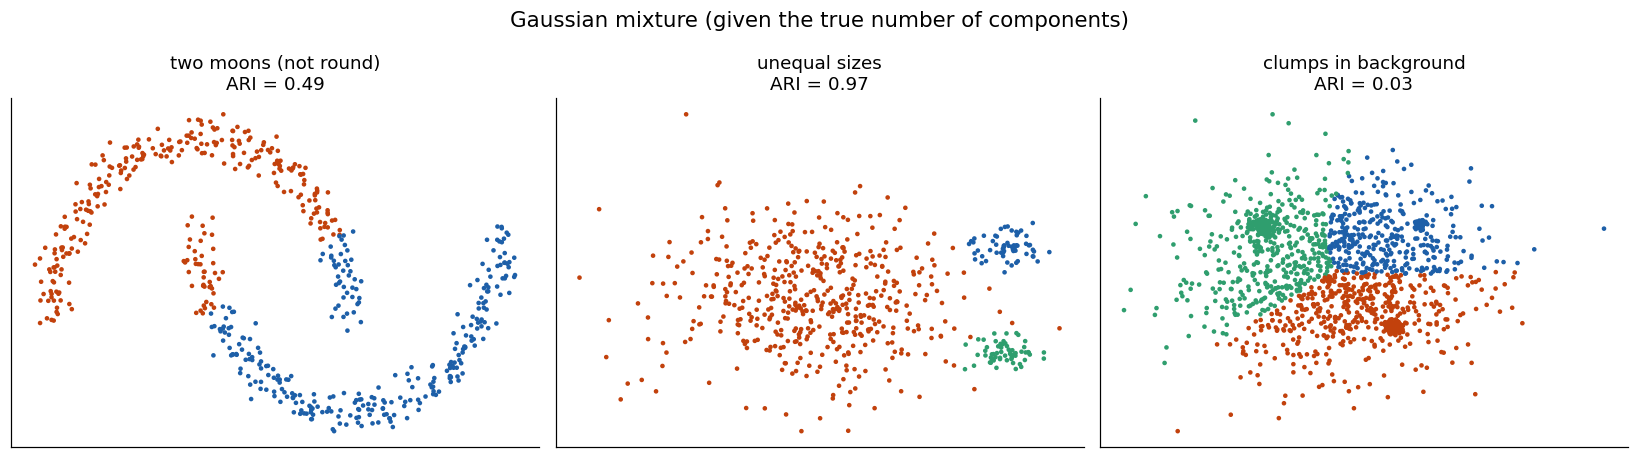

In [10]:
res_gmm = {name: GaussianMixture(k, random_state=0).fit_predict(X) for name, (X, y, k) in datasets.items()}
show_row(res_gmm, "Gaussian mixture (given the true number of components)")

The GMM handles unequal sizes well, since each blob gets its own covariance. It still fails on the moons (they aren't Gaussian), and on the star field it spends its few components on the field. The field isn't one Gaussian.

The fix for the star field is to give it more components and let BIC decide, then call the **tight** components clusters and the **broad** ones background. Let's do it.

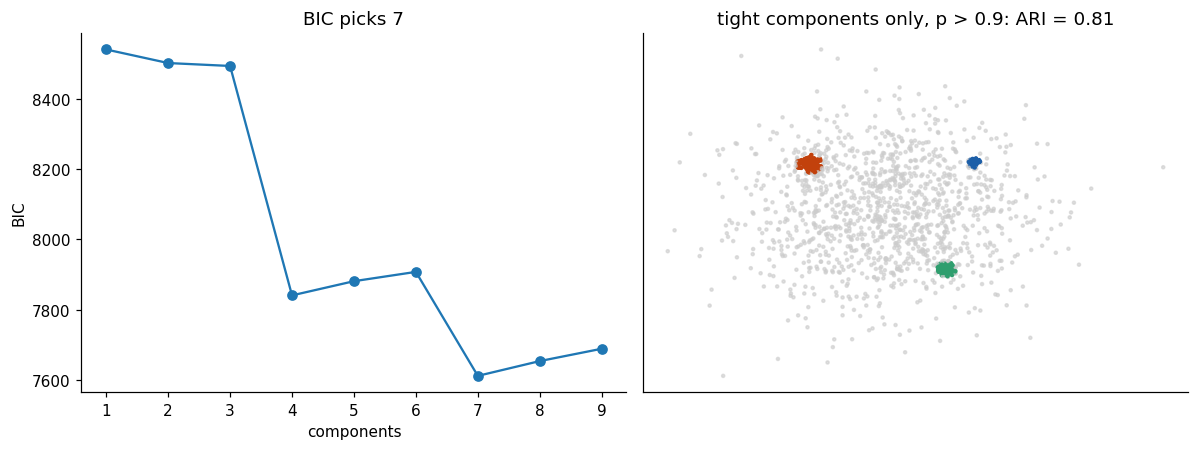

component sizes (sorted): [0.002 0.005 0.017 0.424 0.496 0.579 0.832]


In [11]:
ns = range(1, 10)
fits = [GaussianMixture(n, random_state=0).fit(X_s) for n in ns]
bics = [g.bic(X_s) for g in fits]
best = fits[int(np.argmin(bics))]
size = np.array([np.sqrt(np.linalg.det(c)) for c in best.covariances_])   # blob "area"
tight = np.where(size < 0.1 * np.median(size))[0]
proba = best.predict_proba(X_s)
lab_gmm_sky = np.full(len(X_s), -1)
for new, j in enumerate(tight):
    lab_gmm_sky[proba[:, j] > 0.9] = new

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(list(ns), bics, "o-"); axes[0].set(xlabel="components", ylabel="BIC", title=f"BIC picks {best.n_components}")
axes[1].scatter(*X_s.T, s=4, c=color_of(lab_gmm_sky))
axes[1].set(title=f"tight components only, p > 0.9: ARI = {adjusted_rand_score(y_sky, lab_gmm_sky):.2f}",
            xticks=[], yticks=[])
plt.tight_layout(); plt.show()
print("component sizes (sorted):", np.sort(size).round(3))

---
## 7. Scoreboard and tool-leveling

In [12]:
import pandas as pd
board = pd.DataFrame({
    "k-means": {n: adjusted_rand_score(datasets[n][1], res_km[n]) for n in datasets},
    "DBSCAN": {n: adjusted_rand_score(datasets[n][1], res_db[n]) for n in datasets},
    "GMM (fixed K)": {n: adjusted_rand_score(datasets[n][1], res_gmm[n]) for n in datasets},
}).round(2)
board.loc["clumps in background", "GMM (BIC + tight comps)"] = round(adjusted_rand_score(y_sky, lab_gmm_sky), 2)
board

,k-means,DBSCAN,GMM (fixed K),GMM (BIC + tight comps)
two moons (not round),0.48,1.00,0.49,NaN
unequal sizes,0.22,0.62,0.97,NaN
clumps in background,0.03,0.87,0.03,0.81


| | k-means | DBSCAN / HDBSCAN | Gaussian mixture |
|---|---|---|---|
| A cluster is... | the points nearest a center | a dense region | a Gaussian blob |
| You choose | $k$ | `eps`, `min_samples` | number of components (BIC helps) |
| Can say "no cluster" | no | yes (noise) | yes, with a probability cut |
| Breaks on | non-round, unequal, background | very different densities | non-Gaussian shapes |

There is no best clustering algorithm. There is the algorithm whose assumptions match your physics.

**Tool-leveling: how much tool is this?** All three need no labels, give output you can plot and inspect, and run in a second or two on tens of thousands of points on a laptop.

In [13]:
X_big = np.vstack([toy_sky(seed=s)[0] for s in range(40)])     # 60,000 points
for name, alg in [("k-means", KMeans(3, n_init=1, random_state=0)),
                  ("DBSCAN", DBSCAN(eps=0.5, min_samples=10)),
                  ("GMM (8 comps)", GaussianMixture(8, random_state=0))]:
    t0 = time.perf_counter(); alg.fit(X_big)
    print(f"{name:14s} on {len(X_big):,} points: {time.perf_counter() - t0:.2f} s")

k-means        on 60,000 points: 0.05 s
DBSCAN         on 60,000 points: 6.54 s
GMM (8 comps)  on 60,000 points: 6.55 s


**When is clustering the right-sized tool?**
- The structure you want is "groups of points that are close in some feature space."
- You have no labels, or labels would be expensive.
- You need to explain the result to someone (and check it).

**When should you move up?**
- The structure is a long thin curve (a stellar stream), a ring, or something defined by relationships rather than closeness → graph methods, physics models, or learned representations.
- You *do* have trustworthy labels (from simulation or a curated catalog) → a supervised classifier will usually beat clustering.
- The raw data is images or waveforms, where "close" in pixel space means nothing → learn a representation first (Units 2 and 5).

**Pause and discuss (2 min, with a neighbor):** would an LLM help find star clusters? Where in this workflow, if anywhere, would you use one?

---
## 8. How do you know you're right when there's no answer key?

Everything above was graded against true labels. Real data has none. Two kinds of checks:

1. **Internal checks** use only the clustering itself: silhouette score, stability (does the answer survive a different random seed, a resample, a small change in `eps`?).
2. **Physics checks** use information the algorithm **never saw**. In the lab, you cluster stars on motion and parallax only, then check that each cluster's stars form a tight main sequence in brightness and color. A real cluster passes; a chance grouping of field stars doesn't.

Internal checks tell you the groups are well separated. Only the physics check tells you the groups are *real*.

In [14]:
# A quick stability check: does DBSCAN on the star field give the same answer on half the data?
X_s = datasets["clumps in background"][0]
r = np.random.default_rng(0)
for trial in range(3):
    idx = r.choice(len(X_s), len(X_s) // 2, replace=False)
    lab = DBSCAN(eps=0.1, min_samples=10).fit_predict(X_s[idx])     # half the data, so half min_samples
    print(f"half-sample {trial}: clusters = {lab.max() + 1}, ARI vs truth = {adjusted_rand_score(y_sky[idx], lab):.2f}")

half-sample 0: clusters = 3, ARI vs truth = 0.89
half-sample 1: clusters = 3, ARI vs truth = 0.86
half-sample 2: clusters = 4, ARI vs truth = 0.80


---
## Summary
- Clustering is unsupervised: no labels, the target is a pattern.
- **Features and scaling come first.** They define what "close" means, and they're physics decisions.
- **k-means** finds round, similar-sized groups and puts every point somewhere. **DBSCAN** finds dense regions and allows noise. **GMMs** fit Gaussian blobs and give membership probabilities.
- Choose the algorithm whose assumptions match your data, and always compare against a simpler option.
- Validate with information the algorithm never saw.

**Next:** in the computing lab, you'll find three open clusters in a simulated Gaia catalog and use the color–magnitude diagram to check them. In the assignment, you'll identify pions, kaons and protons from a time-of-flight detector, where a single physics-derived feature turns a hopeless clustering problem into an easy one.